In [1]:
import sys

sys.path.append("../src")
import torch
from datasets.bird_call_photo_latent_mix import BirdCallPhotoLatentMix
from models.diffusion import Diffusion
from models.vae import VAE
from processing.audio import log_mel_to_waveform
from IPython.display import Audio, display
from torchvision.transforms.functional import to_pil_image

/home/rmdluo/miniconda3/envs/birdcallbirdphoto/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
AUDIO_DATASET_PATH = "../data/iNaturalistLatentsAudio"
PHOTO_DATASET_PATH = "../data/iNaturalistLatentsPhoto"
AUDIO_VAE_CHECKPOINT_PATH = (
    "../models/audio_vae/1784428657621265322/photo_vae_final.tar"
)
PHOTO_VAE_CHECKPOINT_PATH = (
    "../models/photo_vae/1784935571103765988/photo_vae_final.tar"
)
AUDIO_DIFFUSION_CHECKPOINT_PATH = "../models/conditional_audio_diffusion/1785032242114494706/conditional_audio_diffusion_final.tar"

diffusion_checkpoint = torch.load(AUDIO_DIFFUSION_CHECKPOINT_PATH, weights_only=False)
vae_checkpoint = torch.load(AUDIO_VAE_CHECKPOINT_PATH, weights_only=False)

diffusion_parameters = diffusion_checkpoint['model_parameters']
vae_parameters = vae_checkpoint['model_parameters']
train_parameters = diffusion_checkpoint['train_parameters']
train_parameters.device = "cuda:1"
print(diffusion_parameters)

DiffusionParameters(input_shape=(4, 16, 40), conditioning_shape=(4, 16, 16), output_shape=(4, 16, 40), conditioning_dim=256, num_train_steps=1000, unet_block_out_channels=(320, 640, 1280), seed=42)


In [3]:
train_dataset = BirdCallPhotoLatentMix(
    AUDIO_DATASET_PATH,
    PHOTO_DATASET_PATH,
    AUDIO_VAE_CHECKPOINT_PATH,
    PHOTO_VAE_CHECKPOINT_PATH,
    split="train",
    audio_first=True,
    num_pairs_per_species=50,
)
val_dataset = BirdCallPhotoLatentMix(
    AUDIO_DATASET_PATH,
    PHOTO_DATASET_PATH,
    AUDIO_VAE_CHECKPOINT_PATH,
    PHOTO_VAE_CHECKPOINT_PATH,
    split="val",
    audio_first=True,
    num_pairs_per_species=50,
)

In [4]:
diffusion = Diffusion(diffusion_parameters)
diffusion.load_state_dict(diffusion_checkpoint['model_state_dict'])
diffusion = diffusion.to(train_parameters.device)
diffusion.eval()

Diffusion(
  (embed_conditioning): Sequential(
    (0): Conv2d(4, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (2): SiLU()
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): GroupNorm(16, 128, eps=1e-05, affine=True)
    (5): SiLU()
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (diffusion): UNet2DConditionModel(
    (conv_in): Conv2d(4, 320, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (time_proj): Timesteps()
    (time_embedding): TimestepEmbedding(
      (linear_1): Linear(in_features=320, out_features=1280, bias=True)
      (act): SiLU()
      (linear_2): Linear(in_features=1280, out_features=1280, bias=True)
    )
    (down_blocks): ModuleList(
      (0): CrossAttnDownBlock2D(
        (attentions): ModuleList(
          (0-1): 2 x Transformer2DModel(
            (norm): GroupNorm(32, 320, eps=1e-06, affine=True)
            (proj_in): Conv

In [5]:
vae = VAE(vae_parameters)
vae.load_state_dict(vae_checkpoint['model_state_dict'])
vae = vae.to(train_parameters.device)
vae.eval()

VAE(
  (encoder): Sequential(
    (0): Conv2d(1, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (act1): SiLU()
      (act2): SiLU()
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
      (residual): Identity()
    )
    (2): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (act1): SiLU()
      (act2): SiLU()
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
      (residual): Identity()
    )
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): ResidualBlock(
      (conv1): Conv2d(128, 128, kernel_size=(3, 3), st

Abert's Towhee


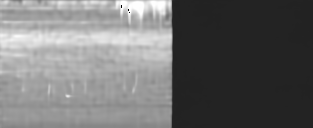

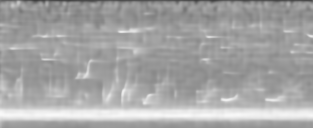

In [6]:
latent_1, latent_2, species = val_dataset[0]
latent_1 = latent_1.to(train_parameters.device)
latent_2 = latent_2.to(train_parameters.device)

samples = diffusion.sample(latent_2.unsqueeze(0), device=train_parameters.device)

print(species)

with torch.no_grad():
    log_mel_example_of_original = vae.decode(latent_1.unsqueeze(0).to(train_parameters.device))
    log_mel_generated = vae.decode(samples[-1].to(train_parameters.device))

display(
    Audio(
        log_mel_to_waveform(log_mel_example_of_original.cpu().squeeze())[0].numpy(),
        rate=16000,
    )
)
display(to_pil_image(log_mel_example_of_original.cpu().squeeze()))

display(
    Audio(
        log_mel_to_waveform(log_mel_generated.cpu().squeeze())[0].numpy(),
        rate=16000,
    )
)
display(to_pil_image(log_mel_generated.cpu().squeeze()))

American Pipit


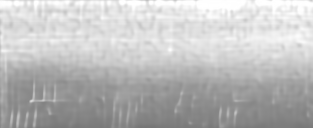

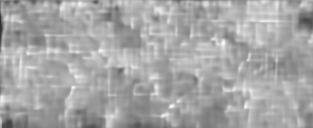

In [7]:
latent_1, latent_2, species = val_dataset[100]
latent_1 = latent_1.to(train_parameters.device)
latent_2 = latent_2.to(train_parameters.device)

samples = diffusion.sample(latent_2.unsqueeze(0), device=train_parameters.device)

print(species)

with torch.no_grad():
    log_mel_example_of_original = vae.decode(latent_1.unsqueeze(0).to(train_parameters.device))
    log_mel_generated = vae.decode(samples[0].to(train_parameters.device))

display(
    Audio(
        log_mel_to_waveform(log_mel_example_of_original.cpu().squeeze())[0].numpy(),
        rate=16000,
    )
)
display(to_pil_image(log_mel_example_of_original.cpu().squeeze()))

display(
    Audio(
        log_mel_to_waveform(log_mel_generated.cpu().squeeze())[0].numpy(),
        rate=16000,
    )
)
display(to_pil_image(log_mel_generated.cpu().squeeze()))

Australasian Figbird


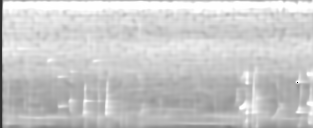

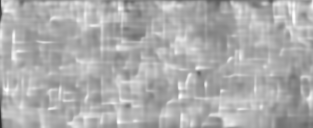

In [8]:
latent_1, latent_2, species = val_dataset[200]
latent_1 = latent_1.to(train_parameters.device)
latent_2 = latent_2.to(train_parameters.device)

samples = diffusion.sample(latent_2.unsqueeze(0), device=train_parameters.device)

print(species)

with torch.no_grad():
    log_mel_example_of_original = vae.decode(latent_1.unsqueeze(0).to(train_parameters.device))
    log_mel_generated = vae.decode(samples[0].to(train_parameters.device))

display(
    Audio(
        log_mel_to_waveform(log_mel_example_of_original.cpu().squeeze())[0].numpy(),
        rate=16000,
    )
)
display(to_pil_image(log_mel_example_of_original.cpu().squeeze()))

display(
    Audio(
        log_mel_to_waveform(log_mel_generated.cpu().squeeze())[0].numpy(),
        rate=16000,
    )
)
display(to_pil_image(log_mel_generated.cpu().squeeze()))

# Plotting Loss Curves

In [9]:
%matplotlib inline

import pandas as pd
import seaborn as sns

epochs = len(diffusion_checkpoint['train_losses']['total_loss'])
losses = pd.DataFrame({
    "total_losses": diffusion_checkpoint['train_losses']['total_loss'] + diffusion_checkpoint['val_losses']['total_loss'],
    "split": ["train"] * epochs + ["val"] * epochs,
    "epoch": list(range(epochs)) + list(range(epochs))
})

<Axes: xlabel='epoch', ylabel='total_losses'>

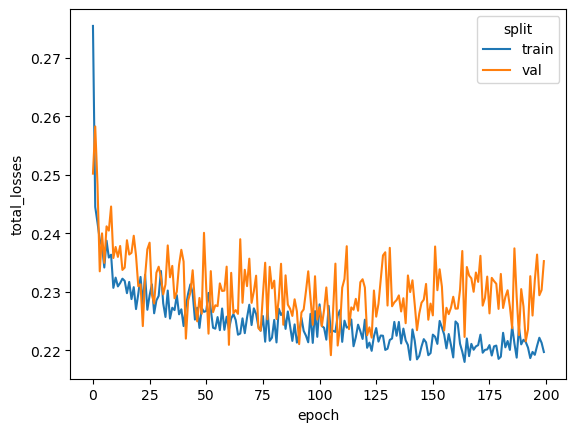

In [10]:
sns.lineplot(
    losses,
    x="epoch",
    y="total_losses",
    hue="split"
)